# Historical UCL results: exploratory analysis
Descriptive analysis of the 2015/16–2025/26 OpenFootball archive. The outcome is the home/draw/away result after 90 minutes. Extra time and penalties remain separate. These charts describe the full archive; they are not predictive evaluation. The former group stage and the 36-team league phase introduced in 2024/25 are kept distinct.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
matches = pd.read_csv(ROOT / "data/processed/ucl_matches.csv", parse_dates=["date"])
manifest = pd.read_csv(ROOT / "data/metadata/ucl_source_manifest.csv")
order = ["H", "D", "A"]
labels = {"H":"Home win", "D":"Draw", "A":"Away win"}
phase_labels = {"league_or_group_phase":"Group / league phase", "knockout_playoff":"Knockout playoff", "knockout":"Other knockout"}
sns.set_theme(style="whitegrid")
print(f"{len(matches):,} matches; {matches.season.nunique()} seasons; {matches.date.min().date()} to {matches.date.max().date()}")

1,497 matches; 11 seasons; 2015-09-15 to 2026-05-30


## Coverage and parsing quality
The table compares parsed row totals to each raw file's declared count. Header agreement validates internal source consistency, not completeness against an independent official archive.

In [2]:
season_summary = matches.groupby("season", sort=True).agg(matches=("season","size"), first_match=("date","min"), last_match=("date","max"), missing_target=("outcome_90m",lambda x:x.isna().sum()))
season_summary["teams"] = matches.groupby("season").apply(lambda g: pd.unique(pd.concat([g.home_team,g.away_team])).size, include_groups=False)
season_summary["header_matches"] = season_summary.index.map(manifest.set_index("season").header_match_count)
season_summary["matches_equal_header"] = season_summary.matches.eq(season_summary.header_matches)
display(season_summary)
quality = pd.Series({
 "parsed matches":len(matches),
 "duplicate date/home/away keys":matches.duplicated(["date","home_team","away_team"]).sum(),
 "missing core fields":matches[["date","home_team","away_team","stage","outcome_90m"]].isna().any(axis=1).sum(),
 "missing 90-minute goals":matches[["regulation_home_goals","regulation_away_goals"]].isna().any(axis=1).sum(),
 "invalid outcomes":(~matches.outcome_90m.isin(order)).sum(),
 "source counts matching parsed counts":manifest.header_match_count.eq(manifest.parsed_match_count).sum(),
})
display(quality.to_frame("value"))

,matches,first_match,last_match,missing_target,teams,header_matches,matches_equal_header
season,,,,,,,
2015-16,125,2015-09-15,2016-05-28,0,32,125,True
2016-17,125,2016-09-13,2017-06-03,0,32,125,True
2017-18,125,2017-09-12,2018-05-26,0,32,125,True
2018-19,125,2018-09-18,2019-06-01,0,32,125,True
2019-20,119,2019-09-17,2020-08-23,0,32,119,True
2020-21,125,2020-10-20,2021-05-29,0,32,125,True
2021-22,125,2021-09-14,2022-05-28,0,32,125,True
2022-23,125,2022-09-06,2023-06-10,0,32,125,True
2023-24,125,2023-09-19,2024-06-01,0,32,125,True


,value
parsed matches,1497
duplicate date/home/away keys,0
missing core fields,0
missing 90-minute goals,0
invalid outcomes,0
source counts matching parsed counts,11


## Outcomes and goals
Outcome proportions are descriptive and can inform the simple frequency baseline. The season charts use proportions/means to account for different match counts.

,matches,share
outcome_90m,,
H,706,0.471610
D,298,0.199065
A,493,0.329325


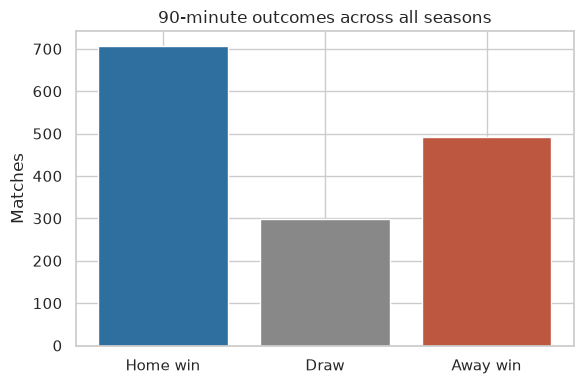

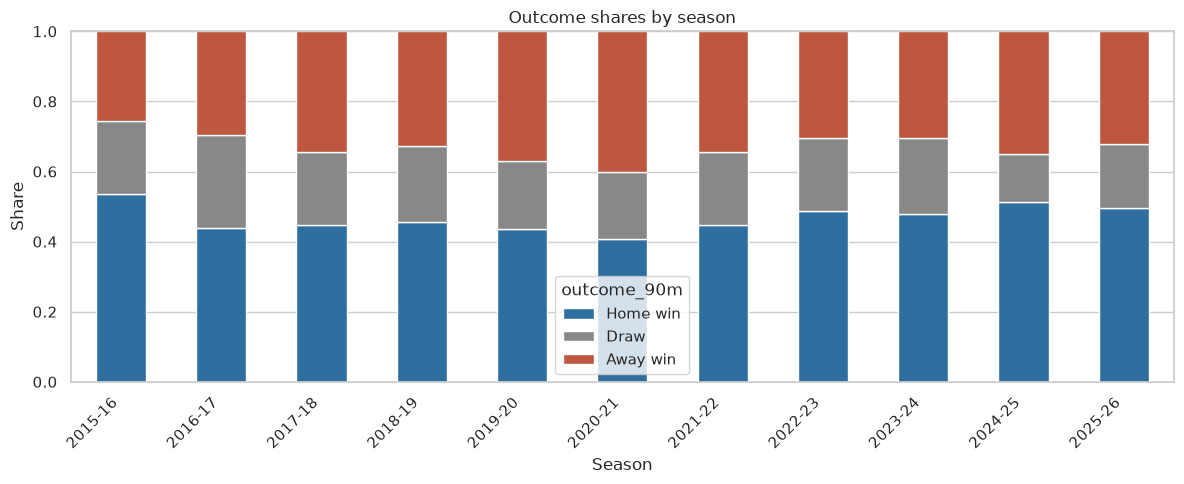

,home_goals,away_goals,total_goals
season,,,
2015-16,1.656,1.104,2.760
2016-17,1.808,1.208,3.016
2017-18,1.784,1.424,3.208
2018-19,1.688,1.232,2.920
2019-20,1.672,1.538,3.210
2020-21,1.456,1.456,2.912
2021-22,1.616,1.408,3.024
2022-23,1.640,1.336,2.976
2023-24,1.712,1.288,3.000


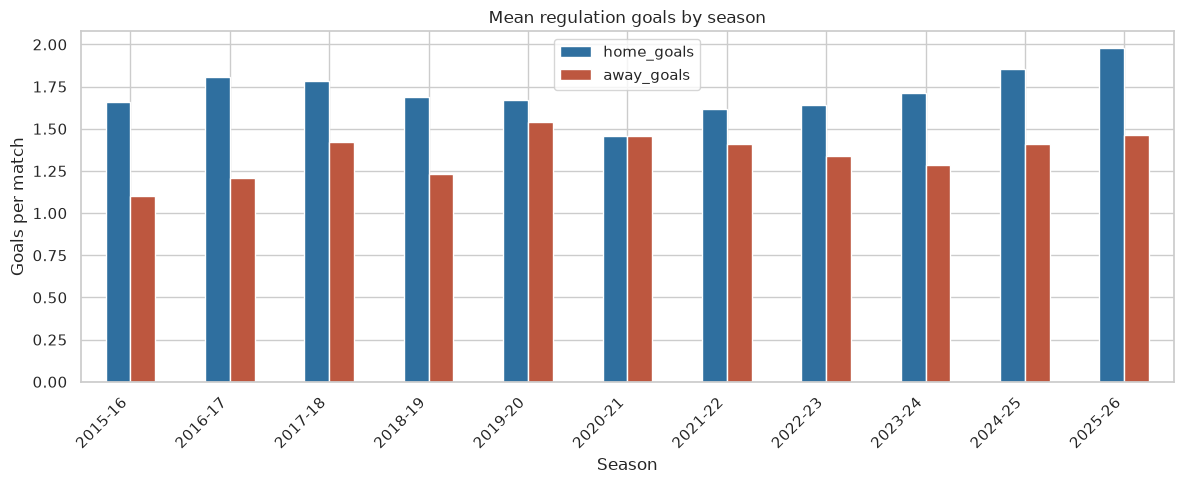

In [3]:
counts = matches.outcome_90m.value_counts().reindex(order,fill_value=0)
display(pd.DataFrame({"matches":counts,"share":counts/counts.sum()}))
fig, ax = plt.subplots(figsize=(6,4))
ax.bar([labels[k] for k in order],counts.values,color=["#2f6f9f","#888888","#bd573f"])
ax.set(title="90-minute outcomes across all seasons",ylabel="Matches")
plt.tight_layout(); plt.show()
by_season = matches.groupby(["season","outcome_90m"]).size().unstack(fill_value=0).reindex(columns=order)
shares = by_season.div(by_season.sum(axis=1),axis=0).rename(columns=labels)
ax = shares.plot(kind="bar",stacked=True,figsize=(12,5),color=["#2f6f9f","#888888","#bd573f"])
ax.set(title="Outcome shares by season",xlabel="Season",ylabel="Share",ylim=(0,1))
plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()
matches["total_goals_90m"] = matches.regulation_home_goals + matches.regulation_away_goals
goals = matches.groupby("season").agg(home_goals=("regulation_home_goals","mean"),away_goals=("regulation_away_goals","mean"),total_goals=("total_goals_90m","mean"))
display(goals.round(3))
ax = goals[["home_goals","away_goals"]].plot(kind="bar",figsize=(12,5),color=["#2f6f9f","#bd573f"])
ax.set(title="Mean regulation goals by season",xlabel="Season",ylabel="Goals per match")
plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()

## Home advantage by format and phase
The table and chart show sample sizes and outcome shares. Phase comparisons are descriptive; 2019/20 had an altered knockout format and the newer league phase is structurally different from the old group stage.

n_matches
format_era           competition_phase               
32_team_group_stage  knockout                     255
                     league_or_group_phase        864
36_team_league_phase knockout                      58
                     knockout_playoff              32
                     league_or_group_phase        288

outcome_90m                                     H      D      A
format_era           competition_phase                         
32_team_group_stage  knockout               0.459  0.188  0.353
                     league_or_group_phase  0.461  0.220  0.319
36_team_league_phase knockout               0.500  0.172  0.328
                     knockout_playoff       0.438  0.219  0.344
                     league_or_group_phase  0.514  0.149  0.337

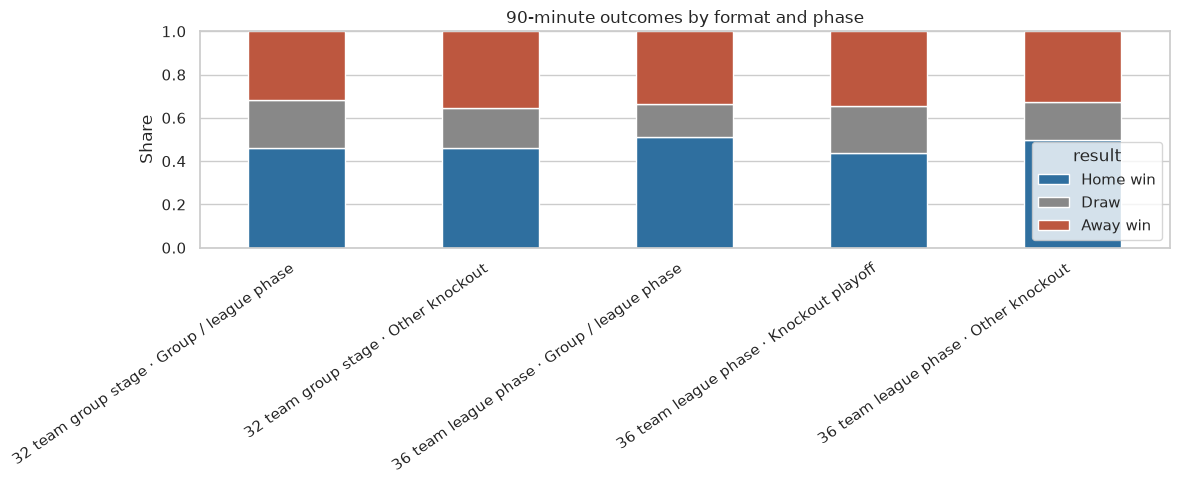

In [4]:
phase = matches.groupby(["format_era","competition_phase","outcome_90m"]).size().rename("n").reset_index()
phase["share"] = phase.n / phase.groupby(["format_era","competition_phase"]).n.transform("sum")
display(matches.groupby(["format_era","competition_phase"]).size().rename("n_matches").to_frame())
display(phase.pivot_table(index=["format_era","competition_phase"],columns="outcome_90m",values="share",fill_value=0).reindex(columns=order).round(3))
phase["label"] = phase.format_era.str.replace("_"," ") + " · " + phase.competition_phase.map(phase_labels)
phase["result"] = phase.outcome_90m.map(labels)
wide = phase.pivot(index="label",columns="result",values="share").fillna(0).reindex(columns=[labels[k] for k in order])
ax = wide.plot(kind="bar",stacked=True,figsize=(12,5),color=["#2f6f9f","#888888","#bd573f"])
ax.set(title="90-minute outcomes by format and phase",xlabel="",ylabel="Share",ylim=(0,1))
plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()

## Team performance within season
Points per match is shown for team-season labels with at least 12 matches. It uses each team's complete season, so it is descriptive only and not a predictive feature. Team names are not canonicalized across seasons; aliases are not merged here.

matches  points_per_match
season  team                                                     
2020-21 Manchester City (ENG)                13          2.615385
2025-26 Arsenal FC (ENG)                     15          2.466667
        FC Bayern München (GER)              14          2.428571
2021-22 Liverpool FC (ENG)                   13          2.384615
2023-24 Real Madrid CF (ESP)                 13          2.384615
2015-16 Real Madrid (ESP)                    13          2.307692
2016-17 Juventus (ITA)                       13          2.307692
2020-21 Chelsea FC (ENG)                     13          2.307692
2018-19 FC Barcelona (ESP)                   12          2.250000
2017-18 Real Madrid (ESP)                    13          2.230769
2022-23 Manchester City (ENG)                13          2.230769
2024-25 FC Internazionale Milano (ITA)       15          2.200000

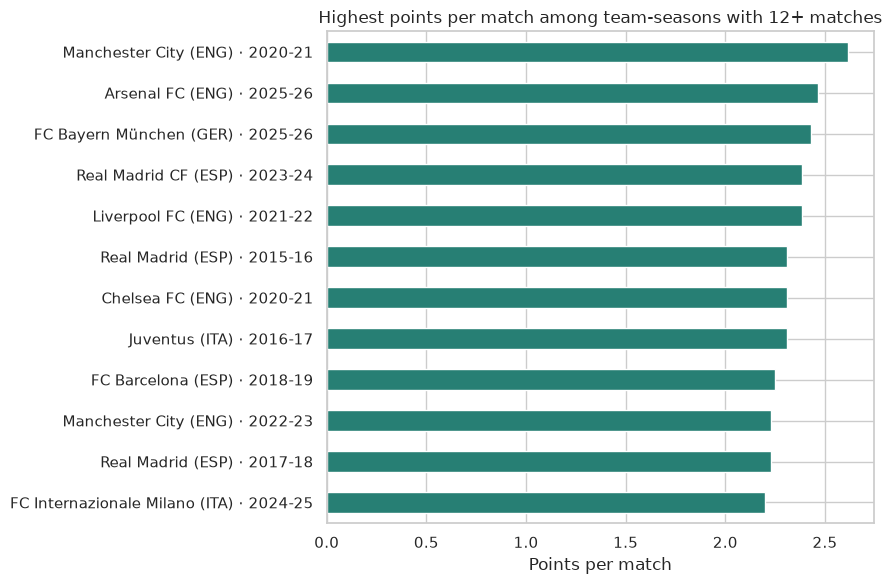

In [5]:
home_points = matches.outcome_90m.map({"H":3,"D":1,"A":0})
away_points = matches.outcome_90m.map({"H":0,"D":1,"A":3})
team_rows = pd.concat([
 pd.DataFrame({"season":matches.season,"team":matches.home_team,"points":home_points}),
 pd.DataFrame({"season":matches.season,"team":matches.away_team,"points":away_points})
],ignore_index=True)
team_season = team_rows.groupby(["season","team"]).agg(matches=("points","size"),points_per_match=("points","mean"))
ranked = team_season[team_season.matches>=12].nlargest(12,"points_per_match").sort_values("points_per_match")
display(ranked.sort_values("points_per_match",ascending=False))
ax=ranked.points_per_match.plot(kind="barh",figsize=(9,6),color="#277f74")
ax.set(title="Highest points per match among team-seasons with 12+ matches",xlabel="Points per match",ylabel="")
ax.set_yticklabels([f"{team} · {season}" for season,team in ranked.index])
plt.tight_layout(); plt.show()

## Interpretation and limitations
- The archive covers 11 seasons but is unbalanced: 2019/20 has 119 matches; both 2024/25 and 2025/26 have 189.
- The old format had 32 teams in eight groups of four; since 2024/25, 36 teams play eight different opponents in a single league phase, followed by a new knockout playoff.
- Knockout samples are smaller. Show sample sizes and avoid strong claims from small subgroup comparisons.
- The source does not include historical starting lineups, attendance, injury reports, or persistent club IDs. Team names vary across years.
- Predictive claims require chronological holdout evaluation with later seasons untouched.